# ICS 635 · Homework 2
## Fine-Tuning an LLM with LoRA

**Name:** Shea Stevens

Use this notebook to implement your own workflow. Read [ASSIGNMENT.pdf](ASSIGNMENT.pdf) for the
full requirements.

- Keep executable code, outputs, and written analysis here.
- Write concise analysis in Markdown cells beside the relevant results.
- Use `record.md` as optional scratch space; it does not need to be submitted.

Save your completed notebook with outputs.

## Setup

Follow `README.md` to set up the environment with `uv sync --locked` (or install packages manually yourself, listed in `pyproject.toml`).

Run the next three cells as they are. They keep the splits, the prompt format, and the scoring consistent, so that results can be compared.

In [9]:
import re

import torch
from datasets import concatenate_datasets, load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer

SEED = 635 # DO NOT MODIFY
MODEL_NAME = "Qwen/Qwen3-1.7B"
ID_TO_LABEL = {0: "negative", 1: "positive", 2: "neutral"}
LABELS = list(ID_TO_LABEL.values())

device_type = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Device: {device_type}")

Device: cuda


In [4]:
data = load_dataset("zeroshot/twitter-financial-news-sentiment")
train = data["train"].shuffle(seed=SEED)
validation = data["validation"].shuffle(seed=SEED)

lora_train = train.select(range(3000))
example_pool = train.select(range(3000, len(train)))
selection = validation.select(range(600))
test = validation.select(range(600, len(validation)))
all_train = concatenate_datasets([lora_train, example_pool])

for name, part in [("lora_train", lora_train), ("example_pool", example_pool), ("selection", selection), ("test", test)]:
    print(f"{name}: {len(part):,} tweets")

lora_train: 3,000 tweets
example_pool: 6,543 tweets
selection: 600 tweets
test: 1,788 tweets


In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def chat_prompt(content):
    """Wrap one user message in Qwen's chat format, with thinking turned off."""
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": content}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False,
    )


def parse_label(generated):
    """Return the first of "positive", "neutral" or "negative" in the text, ignoring case, or "unparsed"."""
    found = re.search(r"positive|neutral|negative", generated.lower())
    return found.group(0) if found else "unparsed"


def score(predictions, gold):
    """Score predicted label names against true label names. An unparsed output is always wrong."""
    per_class = f1_score(gold, predictions, labels=LABELS, average=None, zero_division=0)
    return {
        "macro_f1": round(float(per_class.mean()), 3),
        "accuracy": round(accuracy_score(gold, predictions), 3),
        **{f"f1_{label}": round(float(f1), 3) for label, f1 in zip(LABELS, per_class)},
        "unparsed": list(predictions).count("unparsed"),
    }


print(chat_prompt("Classify this tweet."))
print(parse_label("Neutral."), parse_label("I am not sure"))

<|im_start|>user
Classify this tweet.<|im_end|>
<|im_start|>assistant
<think>

</think>


neutral unparsed


## 1. Inspect the data

Summarize the labels in all four parts and read the tweets in `lora_train`. Calculate the scores of a method that always answers `neutral`.

**Finish this section:** Show the label table, at least five `lora_train` tweets per label, and the always-`neutral` scores on `selection`. In a Markdown cell below, explain what the label means, name two tweets you would have labeled differently, and explain why macro-F1 is the primary metric.

In [6]:
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", None)

# Number of tweets and the share of each label in all four parts.
parts = {"lora_train": lora_train, "example_pool": example_pool, "selection": selection, "test": test}

rows = []
for name, part in parts.items():
    names = pd.Series(part["label"]).map(ID_TO_LABEL)
    counts = names.value_counts().reindex(LABELS, fill_value=0)
    row = {"split": name, "tweets": len(part)}
    for label in LABELS:
        row[f"{label} n"] = counts[label]
        row[f"{label} %"] = round(100 * counts[label] / len(part), 1)
    rows.append(row)

label_table = pd.DataFrame(rows).set_index("split")
label_table

,tweets,negative n,negative %,positive n,positive %,neutral n,neutral %
split,,,,,,,
lora_train,3000,479,16.0,600,20.0,1921,64.0
example_pool,6543,963,14.7,1323,20.2,4257,65.1
selection,600,103,17.2,129,21.5,368,61.3
test,1788,244,13.6,346,19.4,1198,67.0


In [7]:
# Read tweets from lora_train: a seeded random sample of 8 per label (at least 5 required).
# The index is the tweet's row in lora_train, so a tweet can be referred to in the analysis.
train_df = lora_train.to_pandas()
train_df["label_name"] = train_df["label"].map(ID_TO_LABEL)

TWEETS_PER_LABEL = 8
for label in LABELS:
    sample = train_df[train_df["label_name"] == label].sample(n=TWEETS_PER_LABEL, random_state=SEED)
    print(f"\n=== {label} ===")
    display(sample[["text"]])


=== negative ===


,text
1990,Lifeblood of Amazon merchants threatened as coronavirus infects Chinese workers
2973,Falling Oil Prices An Economic Warning Sign | Zero Hedge https://t.co/M57og3233p
2897,UPDATE 1-California toughens drilling oversight in setback for industry
1775,Policy changes to reduce global warming could force a net $1.6 trillion repricing in sectors from energy to agricul… https://t.co/5c5hIGJcc1
63,$AYX - Alteryx Stock Price: More Downside Before Taking Off. Continue reading: https://t.co/RR0zn7EgmY #business #investing #economy
2791,"$ACM - AECOM: Given Disappointing Earnings And No M&A News, ACM Is A Trading Sell. https://t.co/0QlOr3sV7h #stockmarket #markets #stocks"
2804,Fed's Williams: Risks to U.S. economy still to the downside
1442,Finnair cancels 276 flights as unions join solidarity strike #FinnairOyj #Stock #MarketScreener… https://t.co/j4PMDAs2cI



=== positive ===


,text
337,Tesla shares jump as Musk tweets about Cybertruck preorders
895,"Asia shares bounce, hope for best on U.S.-China trade #economy #MarketScreener https://t.co/j8MxRanCYy https://t.co/WSMCSC8eKo"
2249,After a early morning mishap on $SPY $ZM taking control here with $BA $AAPL $AMZN. $SPY $ZM both would be wins now too.
714,Dunkin' Brands Accelerates Growth Into 2020
2365,"Brighthouse Financial EPS beats by $0.27, beats on revenue"
550,French regulator ends probe into supermarket Casino and short-seller Muddy Waters
2030,Medicines Co. shares jump 17% in premarket after report of potential Novartis offer
82,Amazon to create 500 new jobs in Mississippi as it builds a 2nd fulfillment center in the state



=== neutral ===


,text
985,$BOKF - BOK Financial goes ex-dividend tomorrow https://t.co/GwKBOAPDs5
2827,Turkey is trying to stop emergency loans intended to boost its economy during the coronavirus slowdown from fueling… https://t.co/EcSwShpQGl
1485,Delivery Hero Nears Agreement to Buy Woowa in $4 Billion Deal
2500,This former top Obama official says one silver bullet would raise $500 billion in personal-income tax https://t.co/DgBplbAdCO
169,"Fed bombards credit markets with limitless pledge, but investors barely respond https://t.co/KfTfB94OD1"
2420,Sienna Cancer Diagnostics : Key Terms of CEO/Managing Director Employment Contract #SiennaCancerDiagnostics #Stock… https://t.co/g0J3hXxRYg
397,U.S. total weekly active drilling-rig count unchanged at 790: Baker Hughes
2489,"Market participants submitted bids for nearly twice what was on offer in the Fed’s 42-day term repo operation, whic… https://t.co/qIqTKdQtpk"


In [6]:
# Always answer "neutral" on selection.
selection_gold = [ID_TO_LABEL[label] for label in selection["label"]]
always_neutral = ["neutral"] * len(selection_gold)

pd.DataFrame([score(always_neutral, selection_gold)], index=["always neutral (selection)"])

,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed
always neutral (selection),0.253,0.613,0.0,0.0,0.76,0


### Analysis

The label indicates the sentiment of a tweet. These tweets are specifically related to the stock market There are three settings, positive, neutral, and negative. Positive denotes good news or happy content and negative discusses tragic or disappointing news. Neutral is a matter-of-fact statement. 

These sentiments are not entirely accurate though.

For instance, 550 reads neutral to me. Through the lens of the stock market though, it's possible to understand the label. The end of a probe is a positive thing for a stock. 
French regulator ends probe into supermarket Casino and short-seller Muddy Waters

1485 can be see as positive. The potential merger/acquisition is often a good time to buy stock of a company, or speculate on options. 
Delivery Hero Nears Agreement to Buy Woowa in $4 Billion Deal


## 2. Establish baselines

Fit a `TfidfVectorizer` and `LogisticRegression(class_weight="balanced")` pipeline on `lora_train`, and again on `all_train`. Score both on `selection`.

**Finish this section:** Show both pipelines, their settings, and a table of scores and training times here. In a Markdown cell below, explain what each baseline tests and what the gap between them says.

In [7]:
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

pipe_lora = make_pipeline(TfidfVectorizer(),
                        LogisticRegression(class_weight='balanced', max_iter=1000))
start1 = time.perf_counter()
pipe_lora.fit(lora_train['text'], [ID_TO_LABEL[l] for l in lora_train['label']])
train_seconds_1 = time.perf_counter() - start1
lora_pred = pipe_lora.predict(selection['text'])
print(f"Train time 1: {train_seconds_1:.2f} seconds")

pipe_all = make_pipeline(TfidfVectorizer(),
                        LogisticRegression(class_weight='balanced', max_iter=1000))
start2 = time.perf_counter()
pipe_all.fit(all_train['text'], [ID_TO_LABEL[l] for l in all_train['label']])
train_seconds_2 = time.perf_counter() - start2
all_pred = pipe_all.predict(selection['text'])
print(f"Train time 2: {train_seconds_2:.2f} seconds")


baseline_results = pd.DataFrame(
    [
        {"method": "TF-IDF, lora_train (3,000)", "train_seconds": round(train_seconds_1, 2),
         **score(lora_pred, selection_gold)},
        {"method": "TF-IDF, all_train (9,543)", "train_seconds": round(train_seconds_2, 2),
         **score(all_pred, selection_gold)},
    ]
).set_index("method")
baseline_results

Train time 1: 2.72 seconds
Train time 2: 5.94 seconds


,train_seconds,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed
method,,,,,,,
"TF-IDF, lora_train (3,000)",2.72,0.677,0.745,0.557,0.636,0.838,0
"TF-IDF, all_train (9,543)",5.94,0.739,0.788,0.646,0.710,0.862,0


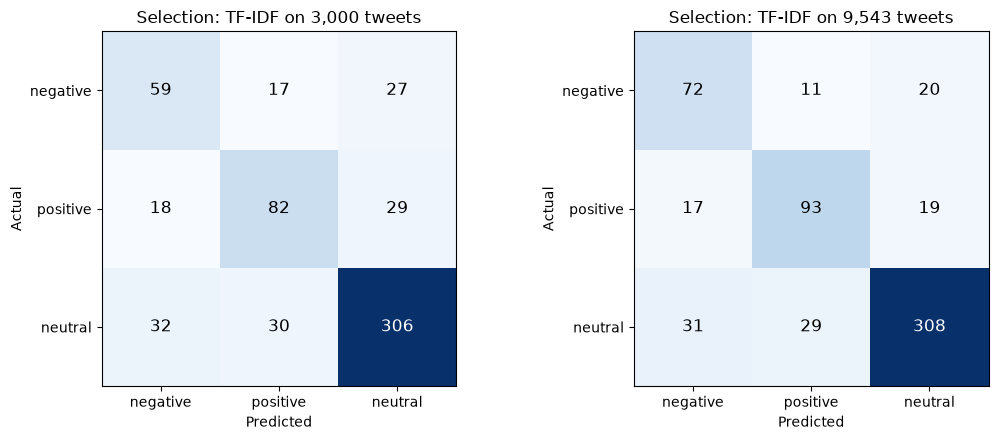

In [8]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


def plot_confusion(ax, gold, preds, title):
    """Draw a confusion matrix: rows are true labels, columns are predicted labels."""
    # Add an "unparsed" column only if some LLM output didn't parse.
    pred_labels = LABELS + ["unparsed"] if "unparsed" in preds else LABELS
    # Gold labels are never "unparsed", so keep only the 3 real rows.
    cm = confusion_matrix(gold, preds, labels=pred_labels)[: len(LABELS)]

    ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set(xticks=range(len(pred_labels)), yticks=range(len(LABELS)),
           xticklabels=pred_labels, yticklabels=LABELS,
           xlabel="Predicted", ylabel="Actual", title=title)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(axes[0], selection_gold, list(lora_pred), "Selection: TF-IDF on 3,000 tweets")
plot_confusion(axes[1], selection_gold, list(all_pred), "Selection: TF-IDF on 9,543 tweets")
plt.tight_layout()
plt.show()

### Analysis


The first baseline is for the LoRA data. This is the 3000 tweets that the LoRA model will be trained on. With a logistic regression as a base, this baseline will be used to compare against our more detailed LoRA model. If the scroes improved, it's drectly related to the model and methods that we use.

The second baseline checks how much the initial baseline would improve given more data. Data is often a bottleneck for model performance, so testing with the full dataset reveals whether more data improves the logistic regression. 

From the confustion matrix, we can see that the predicction scores increase for negative (+13) and positive (+11). The neutral score barely moved (+2). From this test, we see that an increase in data quantity improves scores only in minority classes. From the macro F1 scores we see a similar vector. When comparing the improvement between always neutral and baseline 1 which adds 3000 labeled tweets, we see a significant increase of 0.42. But from baseline 1 to baseline 2, which adds 6543 new labeled tweets, we see a much smaller gap of 0.06. There is a definite improvement, but the increase in data has diminishing returns. 

## 3. Prompt the base model

Load the base model and write batched generation code using the fixed settings in the assignment. Remember to pad on the left. Build every prompt with `chat_prompt`.

Write at least two zero-shot and at least four few-shot prompts. Take few-shot examples only from `example_pool`. Include two prompts with the same examples in a different order, and two with the same number of different examples.

**Finish this section:** Show the text of every prompt, with a placeholder where the tweet goes, and one table of `selection` results: macro-F1, accuracy, per-class F1, predicted-label counts, `unparsed` count, and time. Record your best zero-shot and best few-shot prompts, chosen on `selection` macro-F1.

In [9]:
PROMPTS = {
    "zero_1": "Classify the outlook of this finance tweet as positive, neutral, or negative. Tweet: {tweet}. Answer with one word.",
    "zero_2": "How would you classify this finance tweet? {tweet}. Answer with one word: positive, neutral, or negative.",
    "zero_3": "Describe the outlook of this tweet with one word: {tweet}. Positive, negative, or neutral?"
}

In [ ]:
from transformers import AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, device_map="auto")
model.eval()


def generate(prompts, batch_size=16, max_new_tokens=6):
    """Greedy-generate a short answer for each prompt string. Returns only the new text."""
    tokenizer.padding_side = "left"
    outputs = []
    for start in range(0, len(prompts), batch_size):
        batch = prompts[start:start + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True,
                           add_special_tokens=False).to(model.device)
        with torch.no_grad():
            generated = model.generate(**inputs, do_sample=False, max_new_tokens=max_new_tokens,
                                       pad_token_id=tokenizer.pad_token_id)
        new_tokens = generated[:, inputs["input_ids"].shape[1]:]
        outputs.extend(tokenizer.batch_decode(new_tokens, skip_special_tokens=True))
    return outputs


def run_prompt(template, tweets, batch_size=16):
    """Fill {tweet} in the template, generate, and return (labels, raw outputs, seconds)."""
    prompts = [chat_prompt(template.replace("{tweet}", tweet)) for tweet in tweets]
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    raw = generate(prompts, batch_size=batch_size)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    return [parse_label(r) for r in raw], raw, seconds

Loading weights: 100%|██████████| 311/311 [00:01<00:00, 206.67it/s]


In [11]:
pool_df = example_pool.to_pandas()
pool_df["label_name"] = pool_df["label"].map(ID_TO_LABEL)


def sample_examples(per_label, seed, exclude=()):
    """Pick per_label tweets of each label from example_pool, then shuffle so labels aren't grouped."""
    candidates = pool_df.drop(index=list(exclude))
    picked = candidates.groupby("label_name", group_keys=False).sample(n=per_label, random_state=seed)
    return picked.sample(frac=1, random_state=seed)


def few_shot_template(instruction, examples):
    """Instruction, then each example as Tweet/Answer, then the {tweet} placeholder."""
    parts = [instruction, ""]
    for text, label in zip(examples["text"], examples["label_name"]):
        parts.append(f"Tweet: {' '.join(text.split())}\nAnswer: {label}\n")
    parts.append("Tweet: {tweet}\nAnswer:")
    return "\n".join(parts)

INSTRUCTION = "Classify the outlook of each finance tweet as positive, negative, or neutral. Answer with one word."

set_A = sample_examples(per_label=2, seed=SEED)                               # 6 examples
set_B = sample_examples(per_label=2, seed=SEED + 1, exclude=set_A.index)      # 6 different examples

PROMPTS["few_A"] = few_shot_template(INSTRUCTION, set_A)
PROMPTS["few_A_reversed"] = few_shot_template(INSTRUCTION, set_A.iloc[::-1])  # same tweets, reversed order
PROMPTS["few_B"] = few_shot_template(INSTRUCTION, set_B)                      # same count, different tweets

In [13]:
from collections import Counter

for name, template in PROMPTS.items():
    print(f"=== {name} ===\n{template}\n")

generate([chat_prompt("Warm-up.")] * 4)   # first call is slow; don't let it inflate prompt 1's time

rows, outputs = [], {}
for name, template in PROMPTS.items():
    batch_size = 4 if name.startswith("few_") else 16   # long prompts need smaller batches on 10 GB
    preds, raw, seconds = run_prompt(template, selection["text"], batch_size=batch_size)
    outputs[name] = {"pred": preds, "raw": raw}
    pd.DataFrame({"text": selection["text"], "gold": selection_gold, "pred": preds, "raw": raw}) \
        .to_csv(f"selection_{name}.csv", index=False)   # saved as you go, in case the kernel dies

    counts = Counter(preds)
    rows.append({
        "prompt": name,
        **score(preds, selection_gold),
        **{f"n_{label}": counts.get(label, 0) for label in LABELS},
        "seconds": round(seconds, 1),
    })
    print(f"{name}: macro-F1 {rows[-1]['macro_f1']}, {seconds:.0f}s")

prompt_results = pd.DataFrame(rows).set_index("prompt")
prompt_results

=== zero_1 ===
Classify the outlook of this finance tweet as positive, neutral, or negative. Tweet: {tweet}. Answer with one word.

=== zero_2 ===
How would you classify this finance tweet? {tweet}. Answer with one word: positive, neutral, or negative.

=== zero_3 ===
Describe the outlook of this tweet with one word: {tweet}. Positive, negative, or neutral?

=== few_A ===
Classify the outlook of each finance tweet as positive, negative, or neutral. Answer with one word.

Tweet: U.S. economy adds 225,000 jobs in January; 2019 annual figure revised downward
Answer: positive

Tweet: Boston Scientific $BSX more bullish flow with 5000 May $30 puts being sold $0.72 and the August $40 calls bought $1.30
Answer: positive

Tweet: Egypt's inflation inched higher for a third straight month in urban parts of the country https://t.co/DoJPWNnsC1
Answer: negative

Tweet: Steris declares $0.37 dividend
Answer: neutral

Tweet: $FLOW: SPX FLOW confirms deal to sell substantial portion of former Power an

,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed,n_negative,n_positive,n_neutral,seconds
prompt,,,,,,,,,,
zero_1,0.627,0.622,0.667,0.596,0.618,0,161,237,202,10.4
zero_2,0.555,0.525,0.690,0.530,0.444,0,129,339,132,10.1
zero_3,0.407,0.403,0.590,0.510,0.121,0,229,342,29,12.2
few_A,0.732,0.743,0.743,0.667,0.787,13,142,132,313,37.2
few_A_reversed,0.662,0.668,0.659,0.603,0.725,15,64,249,272,37.3
few_B,0.628,0.605,0.719,0.557,0.607,6,100,295,199,30.8


### Analysis

Wording of the zero shot prompt mattered much more when comparing the prompts. The zero shot prompt that performed the best, zero_1, was written with the most neutral and declarative tone for the model. Interestingly, in the trained prediction results, we see the largest difference in how the model classified 'neutral' tweets. zero_1 performs the best here, with a macro-F1 score of 0.627 and 202 neutral predictions, compared for 132 and 29 for zero_2 and zero_3 respectively, against 268 true neutrals.

Adding in context responses also mattered greatly. Depending on the quality of the examples chosen for the few-shot prompt, and the order in which they were given, responses changed. 

When we compare few_A and few_B, which have the same structure, but different examples, we see that the resulting macro-F1 score is different. This shows that which examples you give matter. We also see that order matters. Between few_A and few_A_reversed, we also see a difference in accuracy. few_A_reversed ends with positively classified tweets. We see the recency bias of the model in the resulting training, where positive predictions jump from 132 to 249. We also see a macro-F1 score decrease from 0.732 to 0.662.

So, after reviewing the scores, I decided to use zero_1 and few_A. 

## 4. Fine-tune with LoRA

Train on `lora_train` with the fixed settings, using your best zero-shot prompt in each training example. Each example is the prompt, the label, and `<|im_end|>\n`. Remember to pad on the right for training and return to left padding for generation.

**Finish this section:** Show the configuration, one complete training example, the trainable parameter count and percentage, training time, peak GPU memory, adapter size, start and end loss, a plot of the training loss, and the `selection` scores of the model reloaded from its saved adapter.

In [ ]:
from datasets import Dataset

BEST_ZERO_SHOT_NAME = "zero_1"  
BEST_ZERO_SHOT = PROMPTS[BEST_ZERO_SHOT_NAME]


def training_text(tweet, label_id):
    """The generation prompt, then the label, then the end-of-turn token."""
    return chat_prompt(BEST_ZERO_SHOT.replace("{tweet}", tweet)) + ID_TO_LABEL[label_id] + "<|im_end|>\n"


texts = [training_text(t, l) for t, l in zip(lora_train["text"], lora_train["label"])]
# Tokenize here: TRL appends <|im_end|> to any "text" that doesn't end with it, and ours ends with "\n".
# A dataset that already has input_ids skips that step, so the model trains on exactly these tokens.
train_dataset = Dataset.from_dict({
    "text": texts,
    "input_ids": [tokenizer(t, add_special_tokens=False)["input_ids"] for t in texts],
})

lengths = [len(ids) for ids in train_dataset["input_ids"]]
print(f"{len(train_dataset)} examples; tokens max {max(lengths)}, mean {sum(lengths) / len(lengths):.0f} (max_length=256)\n")

example = tokenizer.decode(train_dataset[0]["input_ids"])
print(example)
assert example.endswith(ID_TO_LABEL[lora_train[0]["label"]] + "<|im_end|>\n")


3000 examples; tokens max 120, mean 64 (max_length=256)

<|im_start|>user
Classify the outlook of this finance tweet as positive, neutral, or negative. Tweet: Sports Direct International : Britain's Sports Direct to change name to Frasers Group ...… https://t.co/dgK2Mb3MbE. Answer with one word.<|im_end|>
<|im_start|>assistant
<think>

</think>

neutral<|im_end|>



Truncating train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 22540.04 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 182875.21 examples/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
1,5.179012
2,4.629811
3,3.930341
4,3.102304
5,2.725979
6,2.456147
7,2.372512
8,2.137827
9,2.330971
10,1.799061


LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.20.0', base_model_name_or_path='Qwen/Qwen3-1.7B', revision=None, inference_mode=False, r=64, target_modules={'k_proj', 'up_proj', 'q_proj', 'o_proj', 'v_proj', 'down_proj', 'gate_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.1, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, ensure_weight_tying=Fa

,r,lora_alpha,scaling,trainable_params,trainable_pct,train_seconds,peak_gb,adapter_mb,loss_start,loss_end
0,64,32,0.5,69730304,3.895,611.9,16.37,279.0,5.179,1.2847


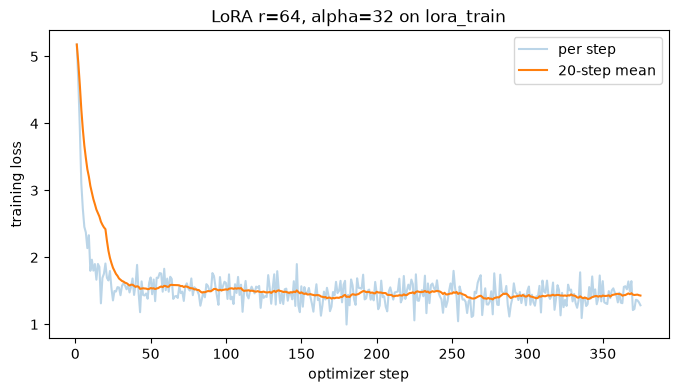

In [ ]:
import gc
import os

import matplotlib.pyplot as plt
from peft import LoraConfig, get_peft_model
from transformers import set_seed
from trl import SFTConfig, SFTTrainer

DEV_RUN = False   # True = bf16 + 64 examples, to smoke-test on the 8 GB card. Must be False for real results.
TARGET_MODULES = ["k_proj", "gate_proj", "v_proj", "up_proj", "q_proj", "o_proj", "down_proj"]


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def train_lora(r, lora_alpha, output_dir, dataset=train_dataset):
    """Train one LoRA adapter with the fixed settings, save it, and return its costs and loss history."""
    set_seed(SEED)
    tokenizer.padding_side = "right"   # right padding for training
    if DEV_RUN:
        dataset = dataset.select(range(64))

    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, dtype=torch.bfloat16 if DEV_RUN else torch.float32, device_map="auto")
    lora_config = LoraConfig(r=r, lora_alpha=lora_alpha, lora_dropout=0.1, bias="none",
                             task_type="CAUSAL_LM", target_modules=TARGET_MODULES)
    peft_model = get_peft_model(base, lora_config)
    trainable, total = peft_model.get_nb_trainable_parameters()

    training_args = SFTConfig(
        output_dir=output_dir,
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        optim="adamw_torch", learning_rate=2e-4, lr_scheduler_type="cosine", num_train_epochs=1,
        bf16=True, dataset_text_field="text", max_length=256,
        save_strategy="no", report_to="none", seed=SEED,
        logging_steps=1,   # log every optimizer step so the start/end loss is exact
    )
    trainer = SFTTrainer(model=peft_model, args=training_args, train_dataset=dataset,
                         processing_class=tokenizer)

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    torch.cuda.synchronize()
    train_seconds = time.perf_counter() - start
    peak_gb = torch.cuda.max_memory_allocated() / 1e9

    peft_model.save_pretrained(output_dir)   # saves only the adapter weights and config
    adapter_mb = os.path.getsize(os.path.join(output_dir, "adapter_model.safetensors")) / 1e6
    losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]

    stats = {"r": r, "lora_alpha": lora_alpha, "scaling": lora_alpha / r,
             "trainable_params": trainable, "trainable_pct": round(100 * trainable / total, 3),
             "train_seconds": round(train_seconds, 1), "peak_gb": round(peak_gb, 2),
             "adapter_mb": round(adapter_mb, 1),
             "loss_start": round(losses[0][1], 4), "loss_end": round(losses[-1][1], 4)}

    del trainer, peft_model, base
    free_gpu()
    tokenizer.padding_side = "left"   # back to left padding for generation
    return stats, losses, lora_config, training_args


# Release the Section 3 base model first: two float32 copies won't fit.
if "model" in globals():
    del model
free_gpu()

ADAPTER_DIR = "adapters/lora_r64_a32"
lora_stats, lora_losses, lora_config, training_args = train_lora(r=64, lora_alpha=32, output_dir=ADAPTER_DIR)

print(lora_config)
print({k: getattr(training_args, k) for k in [
    "per_device_train_batch_size", "gradient_accumulation_steps", "optim", "learning_rate",
    "lr_scheduler_type", "num_train_epochs", "bf16", "max_length", "gradient_checkpointing", "seed"]})
display(pd.DataFrame([lora_stats]))

steps, loss = zip(*lora_losses)
smooth = pd.Series(loss).rolling(20, min_periods=1).mean()
plt.figure(figsize=(8, 4))
plt.plot(steps, loss, alpha=0.3, label="per step")
plt.plot(steps, smooth, label="20-step mean")
plt.xlabel("optimizer step")
plt.ylabel("training loss")
plt.title("LoRA r=64, alpha=32 on lora_train")
plt.legend()
plt.show()


In [18]:
from peft import AutoPeftModelForCausalLM


def score_adapter(adapter_dir, name):
    """Reload a saved adapter onto a fresh base model, score it on selection, save its outputs, then free it."""
    global model   # generate()/run_prompt() read the global model
    # Free any model still held (e.g. from the cell above) before loading: two float32 copies won't fit.
    if "model" in globals():
        del model
    free_gpu()
    model = AutoPeftModelForCausalLM.from_pretrained(
        adapter_dir, dtype=torch.bfloat16 if DEV_RUN else torch.float32, device_map="auto")
    model.eval()
    preds, raw, seconds = run_prompt(BEST_ZERO_SHOT, selection["text"])
    pd.DataFrame({"text": selection["text"], "gold": selection_gold, "pred": preds, "raw": raw}) \
        .to_csv(f"selection_{name}.csv", index=False)
    del model
    free_gpu()
    return preds, seconds


print(f"Adapter on disk: {lora_stats['adapter_mb']} MB")
# Load from disk, not the in-memory model, to confirm what was saved is what was trained.
lora_preds, lora_seconds = score_adapter(ADAPTER_DIR, "lora_r64_a32")
pd.DataFrame([{**score(lora_preds, selection_gold), "seconds": round(lora_seconds, 1)}],
             index=[f"LoRA r=64, alpha=32 ({BEST_ZERO_SHOT_NAME} prompt), selection"])


Adapter on disk: 279.0 MB


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 238.18it/s]


,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed,seconds
"LoRA r=64, alpha=32 (zero_1 prompt), selection",0.848,0.868,0.832,0.814,0.897,0,12.4


### Analysis

When we perform LoRA training, all weights for Qwen3 are unchanged. The attention, MLP weight matrices, embeddings, layer norms, and output layer do not change.

What does change are two small matrices, A and B, which are attached to each of the 7 modules, in every one of the 28 layers. This allows the model to learn a change to W without editing the actual weights of the model.

Because we are attaching these small matrices on top of each module, we are also able to drastically reduce the size that we need. With r=64 and Qwen's shape, we need only 70 million parameters, as shown below, compared to the 1.7 billion parameters in our Qwen 3 model. Comparatively, LoRA matrices are 3.9% the size of the original model. 

| Module | Full W shape (out × in) | Full W params | A (r × in) | B (out × r) | A + B params | Reduction |
|---|---|---|---|---|---|---|
| `q_proj` | 2,048 × 2,048 | 4,194,304 | 64 × 2,048 = 131,072 | 2,048 × 64 = 131,072 | 262,144 | 16.0× |
| `k_proj` | 1,024 × 2,048 | 2,097,152 | 64 × 2,048 = 131,072 | 1,024 × 64 = 65,536 | 196,608 | 10.7× |
| `v_proj` | 1,024 × 2,048 | 2,097,152 | 64 × 2,048 = 131,072 | 1,024 × 64 = 65,536 | 196,608 | 10.7× |
| `o_proj` | 2,048 × 2,048 | 4,194,304 | 64 × 2,048 = 131,072 | 2,048 × 64 = 131,072 | 262,144 | 16.0× |
| `gate_proj` | 6,144 × 2,048 | 12,582,912 | 64 × 2,048 = 131,072 | 6,144 × 64 = 393,216 | 524,288 | 24.0× |
| `up_proj` | 6,144 × 2,048 | 12,582,912 | 64 × 2,048 = 131,072 | 6,144 × 64 = 393,216 | 524,288 | 24.0× |
| `down_proj` | 2,048 × 6,144 | 12,582,912 | 64 × 6,144 = 393,216 | 2,048 × 64 = 131,072 | 524,288 | 24.0× |
| **One layer** | | **50,331,648** | | | **2,490,368** | **20.2×** |
| **All 28 layers** | | **1,409,286,144** (frozen) | | | **69,730,304** (trained) | **20.2×** |

We need two matrices in order to compress the input vector, and then decompress back to the original shape of Qwen's model. With this, we create a reasonable surface for the model to learn characteristics, without disrupting the shape of the overall model. 

From our loss curve, we can learn a few things about our LoRA training. The most noticable is that the loss drastically decreases during its initial epochs. The model starts at 5.18, and after about 50 optimizer steps, the loss plateaus around 1.3-1.5, and maintains the same loss scores for the rest of the training period. This is because the losss is scored on ALL tokens the model received, and since the tweet that is being evaluated is random every time, the model can never approach 0 loss.

A flat loss does not mean the model stopped learning. Since the loss score is calculated based on a per token basis, it can't show the final label accuracy, which is what we are trying to training. The loss curve is insufficient to understand our final model's capabilities correctly, selection scores are needed to augment the evaluation. We see that the models score increases from the initial 0.627 to 0.848, after training zero_1. 


## 5. Compare LoRA settings

Run the other four settings from the assignment's table, resetting the seed and loading a fresh base model each time. You already ran the first (`r=64`, `lora_alpha=32`) in Section 4. Save each adapter under its own name.

**Finish this section:** Show one table with all five runs (trainable parameters, adapter size, training time, peak memory, and `selection` scores) and a plot of macro-F1 against rank with two lines, one for `lora_alpha = r / 2` and one for `lora_alpha = 32`. The rank-64 point belongs on both lines, since 32 = 64 / 2. Record your final setting and the rule you used to choose it.

In [19]:
SETTINGS = [(16, 8), (4, 2), (16, 32), (4, 32)]   # (r, lora_alpha); (64, 32) was run in Section 4

lora_runs = [{**lora_stats, **score(lora_preds, selection_gold), "predict_seconds": round(lora_seconds, 1)}]
loss_histories = {"r64_a32": lora_losses}

for r, alpha in SETTINGS:
    name = f"r{r}_a{alpha}"
    print(f"\n=== Training {name} ===")
    stats, losses, _, _ = train_lora(r=r, lora_alpha=alpha, output_dir=f"adapters/lora_{name}")
    preds, seconds = score_adapter(f"adapters/lora_{name}", f"lora_{name}")
    lora_runs.append({**stats, **score(preds, selection_gold), "predict_seconds": round(seconds, 1)})
    loss_histories[name] = losses
    pd.DataFrame(lora_runs).to_csv("lora_runs.csv", index=False)   # saved as you go, in case the kernel dies
    print(f"{name}: macro-F1 {lora_runs[-1]['macro_f1']}, train {stats['train_seconds']}s, peak {stats['peak_gb']} GB")



=== Training r16_a8 ===


Truncating train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 22303.41 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 174964.36 examples/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
1,5.179012
2,5.168972
3,4.943355
4,4.397798
5,3.881430
6,3.765637
7,3.697627
8,3.269815
9,3.307644
10,2.806066


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 240.23it/s]


r16_a8: macro-F1 0.833, train 610.0s, peak 13.1 GB

=== Training r4_a2 ===


Truncating train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 22984.96 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 173182.38 examples/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


... (7 outputs left out)

Truncating train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 21838.28 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 3000/3000 [00:00<00:00, 176468.53 examples/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
1,5.179012
2,4.489871
3,3.863343
4,3.073052
5,2.715363
6,2.500851
7,2.401708
8,2.173858
9,2.347876
10,1.832641


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 233.39it/s]


r4_a32: macro-F1 0.838, train 608.5s, peak 12.89 GB


,,scaling,trainable_params,trainable_pct,adapter_mb,train_seconds,peak_gb,loss_start,loss_end,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed
r,lora_alpha,,,,,,,,,,,,,,
64,32,0.5,69730304,3.895,279.0,611.9,16.37,5.179,1.2847,0.848,0.868,0.832,0.814,0.897,0
16,8,0.5,17432576,1.003,69.8,610.0,13.10,5.179,1.3457,0.833,0.857,0.817,0.794,0.888,0
4,2,0.5,4358144,0.253,17.5,607.7,12.89,5.179,1.4277,0.805,0.835,0.770,0.776,0.870,0
16,32,2.0,17432576,1.003,69.8,617.1,13.10,5.179,1.2826,0.845,0.867,0.833,0.808,0.895,0
4,32,8.0,4358144,0.253,17.5,608.5,12.89,5.179,1.2877,0.838,0.862,0.814,0.808,0.893,0


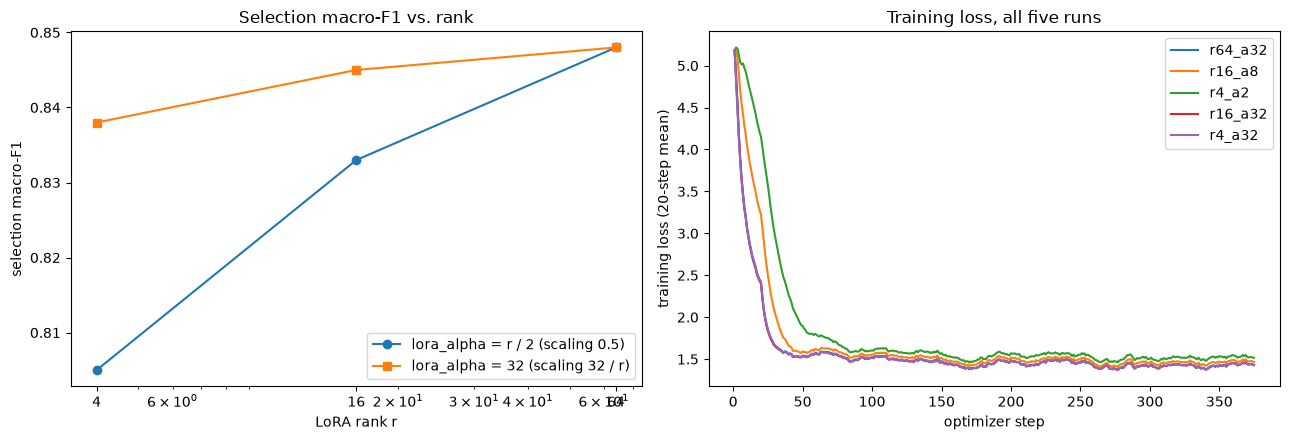

In [20]:
runs = pd.DataFrame(lora_runs).set_index(["r", "lora_alpha"])
display(runs[["scaling", "trainable_params", "trainable_pct", "adapter_mb", "train_seconds", "peak_gb",
              "loss_start", "loss_end", "macro_f1", "accuracy",
              "f1_negative", "f1_positive", "f1_neutral", "unparsed"]])

f1 = runs["macro_f1"]
half = [(r, f1[(r, r // 2)]) for r in (4, 16, 64)]   # lora_alpha = r / 2 (scaling 0.5)
fixed = [(r, f1[(r, 32)]) for r in (4, 16, 64)]      # lora_alpha = 32 (scaling 8, 2, 0.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(*zip(*half), marker="o", label="lora_alpha = r / 2 (scaling 0.5)")
axes[0].plot(*zip(*fixed), marker="s", label="lora_alpha = 32 (scaling 32 / r)")
axes[0].set(xscale="log", xticks=[4, 16, 64], xticklabels=["4", "16", "64"],
            xlabel="LoRA rank r", ylabel="selection macro-F1", title="Selection macro-F1 vs. rank")
axes[0].legend()

for name, losses in loss_histories.items():
    steps, loss = zip(*losses)
    axes[1].plot(steps, pd.Series(loss).rolling(20, min_periods=1).mean(), label=name)
axes[1].set(xlabel="optimizer step", ylabel="training loss (20-step mean)", title="Training loss, all five runs")
axes[1].legend()
plt.tight_layout()
plt.show()


### Analysis

For this section, we are testing and comparing two hyperparameters. r for rank, and a for scaling. Each one has different influences on the final training model.

Rank primarily affects cost. When the final rank is bigger, the resulting adapter has a higher rank meaning more parameters. It's benefits must be closely mosnitored though, as it can easily encounter diminishing returns. Higher rank means more parameters and higher peak memory. Finding the right value is the most important. For our specific examples, with a fixed a, when r was increased from r=4 to r=64, we saw an increase in size from 17.5 MB to 279 MB, while the score change only by 0.01. 

Scaling primarily effects score. When the model learns, this scaling decides how strong the update to each adapter is. From our testing, we see that a=32 produced the best results, as the training loss decreases faster than other settings, and also maintains the same performance across rank settings. From our test cases, we see that a larger a trains faster and scores higher (r=4: 0.805 -> 0.838). The change to scaling has little to no cost; memory, parameters, matrix size, and time all stay the same.

At fixed a=32, macro-F1 barely changed across ranks (0.838-0.848, within noise), while the adapter grew 16x. Rank beyond 4 brought little measurable gain. The lower scores on the a=r/2 line came from small a: those runs trained more slowly, as their loss curves show. The two lines meet at r=64 because it is the same run. So we can conclude that the scaling matters more than the rank for our test set.

For the final selection, based on the highest macro-F1 on selection, I chose r=64 and a=32, with a score of 0.848. These settings are within the group that trained fastest, and scored the best. Within this group, the rank did not affect score very much (r=16: 0.845, r=4: 0.838), so the choice of rank is not meaningful.

From just 600 tweets there is noticable evaluation noise, and with one seed, training variance is also noticable. When comparing against the entire dataset, 600 is a such a small set that a differnce in accuracy can be equated to noise. 1 percentile of difference is 6 tweets. With one seed, we do not know whether said seed is lucky or not. Different seeds provide different randomness, and so a model that gets lucky  may score better. Either using multiple seeds or multiple tests per setting pair to compare final score would be needed. 


## Before final evaluation: record your final choices

Complete this checklist before proceeding to Section 6.

- [x] Both TF-IDF pipelines are fitted and will not be changed.
- [x] The best zero-shot and few-shot prompts are chosen and recorded.
- [x] The final LoRA setting is chosen and its adapter is saved.
- [x] Final prompts and the LoRA setting were chosen on `selection`; nothing used `test`.

| Method | Final configuration |
|---|---|
| TF-IDF on 3,000 tweets | default TfidVectorizer -> LogisticRegression(class_weight='balanced', max_iter=1000), fit on lora_train |
| TF-IDF on 9,543 tweets | Same pipeline and settings, fit on all_train |
| Best zero-shot prompt | zero_1 |
| Best few-shot prompt | few_A |
| Final LoRA `r` and `lora_alpha` | r=64, lora_alpha=32 |

Do not revise these choices after inspecting test results.

## 6. Evaluate once on the test set

Score the six methods on `test` once each. Load the fine-tuned model from its saved adapter. Save the tweets, true labels, and every method's predictions as `test_predictions.csv`, and calculate the final metrics from that table.

**Finish this section:** Show one comparison table (macro-F1, accuracy, per-class F1, `unparsed` count, and prediction time per 1,000 tweets) and confusion matrices for the best zero-shot prompt and the fine-tuned model. Label every result as a test result.

In [23]:
if "model" in globals():
    del model
import sys; sys.last_traceback = sys.last_value = sys.last_exc = None
free_gpu()
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")

6.826630144 GB allocated


In [ ]:
# Generate test predictions for all six methods and measure prediction time.
# Save test_predictions.csv with one row per tweet.

# Final choices, copied from the checklist above. All were chosen on selection; do not change them after this runs.
BEST_FEW_SHOT_NAME = "few_A"   # best few-shot macro-F1 on selection (0.732)
FINAL_R, FINAL_ALPHA = 64, 32  
FINAL_ADAPTER_DIR = f"adapters/lora_r{FINAL_R}_a{FINAL_ALPHA}"
assert os.path.exists(os.path.join(FINAL_ADAPTER_DIR, "adapter_model.safetensors")), FINAL_ADAPTER_DIR
assert not DEV_RUN, "DEV_RUN adapters are smoke tests, not final models"

test_tweets = list(test["text"])
test_gold = [ID_TO_LABEL[label] for label in test["label"]]

METHODS = {   # column name in test_predictions.csv -> display name
    "always_neutral": "1. Always neutral",
    "tfidf_3000": "2. TF-IDF on 3,000 tweets",
    "tfidf_9543": "3. TF-IDF on 9,543 tweets",
    "zero_shot": f"4. Best zero-shot ({BEST_ZERO_SHOT_NAME})",
    "few_shot": f"5. Best few-shot ({BEST_FEW_SHOT_NAME})",
    "lora": f"6. LoRA r={FINAL_R}, alpha={FINAL_ALPHA}",
}
test_preds, test_seconds = {}, {}


def save_test_predictions():
    """Write every method finished so far, so a crashed kernel doesn't lose the LLM runs."""
    pd.DataFrame({"text": test_tweets, "gold": test_gold, **test_preds}).to_csv("test_predictions.csv", index=False)


def timed(fn):
    start = time.perf_counter()
    result = fn()
    return result, time.perf_counter() - start


# Methods 1-3: no GPU. The TF-IDF pipelines are the ones fitted in Section 2; they are not refit.
test_preds["always_neutral"], test_seconds["always_neutral"] = timed(lambda: ["neutral"] * len(test_tweets))
for col, pipe in [("tfidf_3000", pipe_lora), ("tfidf_9543", pipe_all)]:
    preds, test_seconds[col] = timed(lambda: list(pipe.predict(test_tweets)))
    test_preds[col] = preds
save_test_predictions()

# Methods 4-5: the base model, with the same batch sizes as in Section 3.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, device_map="auto")
model.eval()
generate([chat_prompt("Warm-up.")] * 4)   # keep the first-call cost out of the timing
for col, name, batch_size in [("zero_shot", BEST_ZERO_SHOT_NAME, 16), ("few_shot", BEST_FEW_SHOT_NAME, 4)]:
    preds, raw, test_seconds[col] = run_prompt(PROMPTS[name], test_tweets, batch_size=batch_size)
    test_preds[col] = preds
    test_preds[f"{col}_raw"] = raw
    save_test_predictions()
    print(f"{METHODS[col]}: {test_seconds[col]:.0f}s")
del model
free_gpu()

# Method 6: the fine-tuned model, loaded from its saved adapter, with the zero-shot prompt it was trained on.
model = AutoPeftModelForCausalLM.from_pretrained(FINAL_ADAPTER_DIR, dtype=torch.float32, device_map="auto")
model.eval()
generate([chat_prompt("Warm-up.")] * 4)
preds, raw, test_seconds["lora"] = run_prompt(BEST_ZERO_SHOT, test_tweets, batch_size=16)
test_preds["lora"], test_preds["lora_raw"] = preds, raw
save_test_predictions()
print(f"{METHODS['lora']}: {test_seconds['lora']:.0f}s")
del model
free_gpu()

print(f"Saved test_predictions.csv: {len(test_tweets)} tweets, columns {list(pd.read_csv('test_predictions.csv').columns)}")

Loading weights: 100%|██████████| 311/311 [00:01<00:00, 206.54it/s]


4. Best zero-shot (zero_1): 31s
5. Best few-shot (few_A): 110s


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 233.30it/s]


6. LoRA r=64, alpha=32: 37s
Saved test_predictions.csv: 1788 tweets, columns ['text', 'gold', 'always_neutral', 'tfidf_3000', 'tfidf_9543', 'zero_shot', 'zero_shot_raw', 'few_shot', 'few_shot_raw', 'lora', 'lora_raw']


,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed,seconds_per_1000
method (test),,,,,,,
1. Always neutral,0.267,0.670,0.000,0.000,0.802,0,0.00
"2. TF-IDF on 3,000 tweets",0.653,0.748,0.513,0.602,0.845,0,0.01
"3. TF-IDF on 9,543 tweets",0.726,0.794,0.613,0.694,0.870,0,0.01
4. Best zero-shot (zero_1),0.590,0.595,0.615,0.531,0.624,2,17.43
5. Best few-shot (few_A),0.698,0.746,0.651,0.630,0.812,17,61.66
"6. LoRA r=64, alpha=32",0.841,0.882,0.781,0.824,0.917,0,20.61


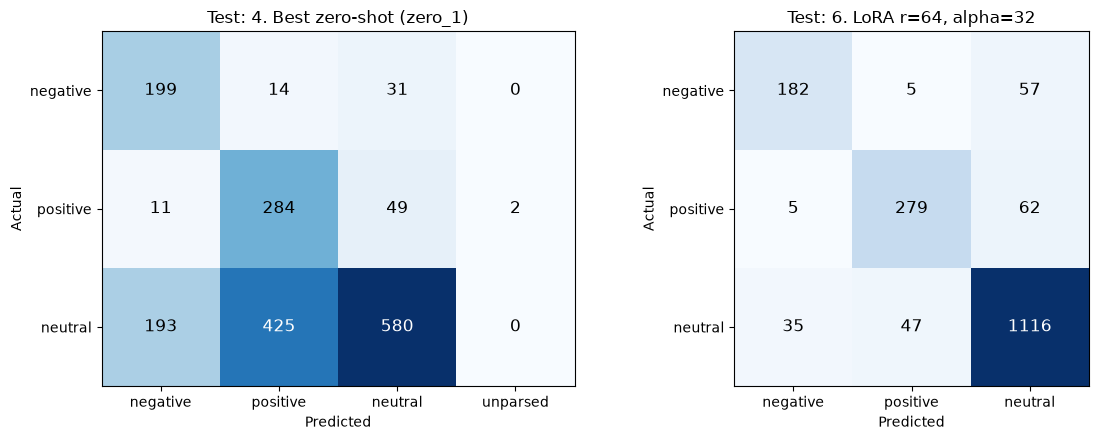

In [25]:
# Calculate the scores and confusion matrices from test_predictions.csv, and add the prediction times measured above.

# keep_default_na=False: a tweet or raw output like "NA" or "None" stays a string instead of becoming NaN.
results = pd.read_csv("test_predictions.csv", keep_default_na=False)
assert len(results) == len(test) and list(results["gold"]) == test_gold

test_rows = []
for col, name in METHODS.items():
    test_rows.append({
        "method (test)": name,
        **score(list(results[col]), list(results["gold"])),
        "seconds_per_1000": round(1000 * test_seconds[col] / len(results), 2),
    })
test_results = pd.DataFrame(test_rows).set_index("method (test)")
display(test_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_confusion(axes[0], list(results["gold"]), list(results["zero_shot"]), f"Test: {METHODS['zero_shot']}")
plot_confusion(axes[1], list(results["gold"]), list(results["lora"]), f"Test: {METHODS['lora']}")
plt.tight_layout()
plt.show()

In [ ]:
# this cell is just so that I don't keep using gpu time on the portal
# Save what Section 7 needs, so it can run on a laptop without the GPU or the models.
import json

with open("section6_state.json", "w") as f:
    json.dump({
        "test_seconds": test_seconds,          # prediction time per method
        "methods": METHODS,                    # column name -> display name
        "best_zero_shot_name": BEST_ZERO_SHOT_NAME,
        "best_few_shot_name": BEST_FEW_SHOT_NAME,
        "final_r": FINAL_R,
        "final_alpha": FINAL_ALPHA,
        "loss_histories": loss_histories,      # for redrawing loss curves if needed
    }, f, indent=2)

prompt_results.to_csv("prompt_results.csv")       # Section 3 table
baseline_results.to_csv("baseline_results.csv")   # Section 2 table
test_results.to_csv("test_results.csv")           # Section 6 table
print("Saved section6_state.json, prompt_results.csv, baseline_results.csv, test_results.csv")


Saved section6_state.json, prompt_results.csv, baseline_results.csv, test_results.csv


### Analysis

Starting with the macro-F1 scores, we see that our predicted best model settings of r=64, a=32 hold true as the best model. With the exception of the always neutral model, all models except always neutral scored slightly lower macro-F1 on test than on selection. The predicted best model score decreased the least, with a difference of 0.007 when compared to 0.013-0.037. This is because we use a larger dataset. The test set becomes larger as a result, so we see less noise and luck in prediction comparison. 

The most noticeable change between the confusion matrix is the recall on neutral tweets. With the untrained zero-shot, we see neutral tweets largely divided between positive and neutral predictions (425 vs 580). After LoRA training, this is almost entirely shifted to a correct neutral prediction (1116 correct vs 82 incorrect). Negative and positive prediction flips also decreased, from 25 to 10. We also see a larger count of positive and negative votes being predicted as neutrals, up 26 for negative and 13 for positive. The tradeoff is that we see a decrease in negative recall, from 199 to 182. The model became more accurate overall, but i's priorities shifted during learning. 

Across our methods, we see that LoRA is the clear winner. From the macro-F1 score, we see that our particular LoRA model outperforms with its score of 0.841. Against the untrained baseline, that's an improvement of 0.19 against TF-IDF on 3000 tweets. Against untrained Qwen model, the impovement is 0.251. That's not to discount the second ranked model, TF-IDF, 9543 tweets. This model has a reasonable accuracy, (0.726, down 0.115 from LoRA), but shines with it's speed at which it predicts. The  TF-IDF on 9543 tweets beats both our best few-shot and zero-shot with Qwen (0.698 and 0.590), with better performance times as well. Since TF-IDF is not LLM based, it can make near instant predictions, while our LLM's ranged from 17.4s to 61.7s. It was particularly slow for the few shot, due to the larger context window needed to  be parsed by the model to make a prediction.

## 7. Analyze the failures

Read the errors. They come from `test`, so use them to explain your results and inform your recommendation, not to change any prompt or model.

**Finish this section:** Define at least three slices of `test`, and report the number of tweets and the macro-F1 of methods 3, 4 and 6 on each slice and on the rest of `test`. Find the tweets that methods 2 to 6 all got wrong, read at least 15 of them chosen with seed 635, mark each as mislabeled, ambiguous or hard with one line on why, and count the marks.

In [11]:
# Resume here on a laptop (no GPU needed). First run: the three Setup cells,
# the pandas cell in Section 1, and the plot_confusion cell in Section 2. Then run this cell.
import json

import pandas as pd
from IPython.display import display

with open("section6_state.json") as f:
    state = json.load(f)
test_seconds = state["test_seconds"]
METHODS = state["methods"]
BEST_ZERO_SHOT_NAME, BEST_FEW_SHOT_NAME = state["best_zero_shot_name"], state["best_few_shot_name"]
FINAL_R, FINAL_ALPHA = state["final_r"], state["final_alpha"]

test_tweets = list(test["text"])
test_gold = [ID_TO_LABEL[label] for label in test["label"]]
results = pd.read_csv("test_predictions.csv", keep_default_na=False)
assert list(results["gold"]) == test_gold, "test split differs: check SEED and the Setup cells"

test_results = pd.read_csv("test_results.csv", index_col=0)
display(test_results)


,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed,seconds_per_1000
method (test),,,,,,,
1. Always neutral,0.267,0.670,0.000,0.000,0.802,0,0.00
"2. TF-IDF on 3,000 tweets",0.653,0.748,0.513,0.602,0.845,0,0.01
"3. TF-IDF on 9,543 tweets",0.726,0.794,0.613,0.694,0.870,0,0.01
4. Best zero-shot (zero_1),0.590,0.595,0.615,0.531,0.624,2,17.43
5. Best few-shot (few_A),0.698,0.746,0.651,0.630,0.812,17,61.66
"6. LoRA r=64, alpha=32",0.841,0.882,0.781,0.824,0.917,0,20.61


In [ ]:
import numpy as np

text = results["text"]
SLICES = {   # yes/no rules computed from the tweet text
    "has $ticker": text.str.contains(r"\$[A-Za-z]{1,5}\b"),
    "has link": text.str.contains(r"https?://"),
    "cut off (… or ...)": text.str.contains(r"…|\.\.\."),
    "8 words or fewer": text.str.split().str.len() <= 8,
}
SLICE_METHODS = {"tfidf_9543": "3. TF-IDF 9,543", "zero_shot": "4. Zero-shot", "lora": "6. LoRA"}


def macro_f1(gold, preds):
    return f1_score(gold, preds, labels=LABELS, average="macro", zero_division=0)


def lead_interval(part, n_boot=1000):
    """95% bootstrap interval for LoRA's macro-F1 lead over TF-IDF 9,543 within one part of test."""
    rng = np.random.default_rng(SEED)
    gold, lora, tfidf = (part[col].to_numpy() for col in ("gold", "lora", "tfidf_9543"))
    leads = []
    for _ in range(n_boot):
        i = rng.integers(0, len(part), len(part))
        leads.append(macro_f1(gold[i], lora[i]) - macro_f1(gold[i], tfidf[i]))
    low, high = np.percentile(leads, [2.5, 97.5])
    return f"[{low:+.3f}, {high:+.3f}]"


slice_rows = []
for slice_name, in_slice in SLICES.items():
    for part_name, mask in [("in slice", in_slice), ("rest of test", ~in_slice)]:
        part = results[mask]
        counts = part["gold"].value_counts()
        f1s = {name: macro_f1(part["gold"], part[col]) for col, name in SLICE_METHODS.items()}
        slice_rows.append({
            "slice": slice_name, "part": part_name, "tweets": len(part),
            **{f"n_{label}": counts.get(label, 0) for label in LABELS},
            **{name: round(f1, 3) for name, f1 in f1s.items()},
            "LoRA lead vs 3": round(f1s["6. LoRA"] - f1s["3. TF-IDF 9,543"], 3),
            "95% CI of lead vs 3": lead_interval(part),
            "LoRA lead vs 4": round(f1s["6. LoRA"] - f1s["4. Zero-shot"], 3),
        })

slice_table = pd.DataFrame(slice_rows).set_index(["slice", "part"])
slice_table

tweets  n_negative  n_positive  n_neutral  \
slice              part                                                      
has $ticker        in slice         263          31          90        142   
                   rest of test    1525         213         256       1056   
has link           in slice         835         110         134        591   
                   rest of test     953         134         212        607   
cut off (… or ...) in slice         333          27          45        261   
                   rest of test    1455         217         301        937   
8 words or fewer   in slice         376          59          62        255   
                   rest of test    1412         185         284        943   

                                 3. TF-IDF 9,543  4. Zero-shot  6. LoRA  \
slice              part                                                   
has $ticker        in slice                0.741         0.635    0.838   
                   rest of test            0.719         0.581    0.842   
has link           in slice                0.685         0.546    0.817   
                   rest of test            0.758         0.629    0.857   
cut off (… or ...) in slice                0.655         0.506    0.805   
                   rest of test            0.734         0.604    0.844   
8 words or fewer   in slice                0.758         0.628    0.888   
                   rest of test            0.716         0.579    0.828   

                                 LoRA lead vs 3 95% CI of lead vs 3  \
slice              part                                               
has $ticker        in slice               0.096    [+0.035, +0.168]   
                   rest of test           0.122    [+0.095, +0.151]   
has link           in slice               0.133    [+0.087, +0.176]   
                   rest of test           0.099    [+0.064, +0.134]   
cut off (… or ...) in slice               0.150    [+0.071, +0.227]   
                   rest of test           0.111    [+0.081, +0.138]   
8 words or fewer   in slice               0.130    [+0.074, +0.190]   
                   rest of test           0.111    [+0.083, +0.143]   

                                 LoRA lead vs 4  
slice              part                          
has $ticker        in slice               0.203  
                   rest of test           0.261  
has link           in slice               0.271  
                   rest of test           0.228  
cut off (… or ...) in slice               0.299  
                   rest of test           0.240  
8 words or fewer   in slice               0.260  
                   rest of test           0.249

In [ ]:
WRONG_METHODS = ["tfidf_3000", "tfidf_9543", "zero_shot", "few_shot", "lora"]   # methods 2-6

all_wrong = results[results[WRONG_METHODS].ne(results["gold"], axis=0).all(axis=1)]
print(f"{len(all_wrong)} of {len(results)} test tweets were wrong for every one of methods 2-6")
display(all_wrong["gold"].value_counts())

to_read = all_wrong.sample(n=min(15, len(all_wrong)), random_state=SEED)
display(to_read[["text", "gold"] + WRONG_METHODS])

# Template for the marks cell below: copy these lines into MARKS and fill in each mark and reason.
for i, row in to_read.iterrows():
    print(f'    {i}: ("", ""),   # gold={row["gold"]}: {row["text"][:70]}')


45 of 1788 test tweets were wrong for every one of methods 2-6


gold
neutral     18
positive    16
negative    11
Name: count, dtype: int64

,text,gold,tfidf_3000,tfidf_9543,zero_shot,few_shot,lora
723,Oil pared losses amid signs that Saudi Arabia and Russia are making progress toward an agreement to curb crude outp… https://t.co/d8GzSKGYQE,positive,neutral,neutral,neutral,neutral,neutral
203,$ITRN - Margins suffer at Ituran Location in Q3 https://t.co/cCI94Csl3s,neutral,negative,negative,negative,negative,negative
1563,Howard Bancorp (NASDAQ:HBMD) Shareholders Have Enjoyed A 54% Share Price Gain,neutral,positive,positive,positive,positive,positive
910,$XLU - XLU Weekly: The Relief Rally From 43.44s Stalls At 58.09s. https://t.co/0QF67WMAAr #investing #markets #economy,negative,positive,positive,neutral,neutral,neutral
101,CME : Volatility in New York gold prices impacting liquidity in London - LBMA #CME #Stock #MarketScreener… https://t.co/8ILGYoJHzS,negative,neutral,neutral,neutral,neutral,neutral
861,Fiat reaches settlement with Italy tax agency over Chrysler value claim,positive,neutral,neutral,neutral,neutral,neutral
640,Here is a list of companies that have suspended dividends or stopped stock buybacks in April https://t.co/JUYLRQJyGp,negative,neutral,neutral,neutral,neutral,neutral
1683,"Boeing 737 Max Net Orders Rise to -73 YTD in Nov. From -93 Oct. Yes, negative",positive,negative,negative,negative,negative,negative
1483,SoftBank's Oyo reveals over $330 million annual loss; revenue surges https://t.co/sboVq3nnEm https://t.co/FNiIij62NJ,neutral,negative,positive,negative,negative,negative
1450,10Y Yield LOD 1.7620%,negative,neutral,neutral,neutral,neutral,neutral


    723: ("", ""),   # gold=positive: Oil pared losses amid signs that Saudi Arabia and Russia are making pr
    203: ("", ""),   # gold=neutral: $ITRN - Margins suffer at Ituran Location in Q3 https://t.co/cCI94Csl3
    1563: ("", ""),   # gold=neutral: Howard Bancorp (NASDAQ:HBMD) Shareholders Have Enjoyed A 54% Share Pri
    910: ("", ""),   # gold=negative: $XLU - XLU Weekly: The Relief Rally From 43.44s Stalls At 58.09s. http
    101: ("", ""),   # gold=negative: CME : Volatility in New York gold prices impacting liquidity in London
    861: ("", ""),   # gold=positive: Fiat reaches settlement with Italy tax agency over Chrysler value clai
    640: ("", ""),   # gold=negative: Here is a list of companies that have suspended dividends or stopped s
    1683: ("", ""),   # gold=positive: Boeing 737 Max Net Orders Rise to -73 YTD in Nov. From -93 Oct. Yes, n
    1483: ("", ""),   # gold=neutral: SoftBank's Oyo reveals over $330 million annual loss; revenue surges h
    1450: ("", ""),

In [ ]:

# My reading of each sampled tweet: (mark, one-line reason). Marks: mislabeled, ambiguous, hard.
MARKS = {
    # paste the 15 template lines printed above, then fill in each mark and reason, e.g.
    # 723: ("hard", "Oil 'pared losses' is a recovery, so bullish for oil, but the tweet starts with 'losses'"),
    723: ("hard", "'pared losses' is a recovery, so is actually good news, not bad."),
    203: ("mislabeled", "margins suffering are negative, although the margin is still positive"),
    1563: ("mislabeled","share price gain should be a positive connotation"),
    910: ("hard", "Rally is a positive term and stalls is a negative term, so is difficult to discern which is more important."),
    101: ("hard","no explicit negative term, but markets don't likee volatility."),
    861: ("hard","no explicit positive term, but markets like settlements, since the stock should  quickly stabilize afterwards"),
    640: ("hard","it is not good news that dividends have been suspended, as it directly affects shareholders."),
    1683: ("ambiguous","describes a rise, but then also has a comment about still being negative ytd."),
    1483: ("hard","discusses a loss and a revenue surge, discerning which is more important is difficult"),
    1450: ("hard","short, only numbers, would have to have deeper understanding of stocks"),
    1728: ("ambiguous","'could bounce high' is speculative"),
    1167: ("hard","impacting is largely negative, but is about a global pandemic affecting the market"),
    96: ("hard","tweet has rises, but is about a survey and not about direct stock value"),
    535: ("ambiguous","news of new cars should drive market interest but don't necessarily drive the market"),
    1063: ("hard","demand for paycheck protection loans means instability in the job market, which is bad"),
}

VALID_MARKS = {"mislabeled", "ambiguous", "hard"}
assert len(MARKS) >= 15 and set(MARKS) <= set(to_read.index), "mark each sampled tweet"
assert all(mark in VALID_MARKS for mark, _ in MARKS.values()), f"marks must be one of {VALID_MARKS}"

marks = pd.DataFrame(
    [{"text": results.loc[i, "text"], "gold": results.loc[i, "gold"], "mark": mark, "why": why}
     for i, (mark, why) in MARKS.items()],
    index=pd.Index(list(MARKS), name="test row"),
)
display(marks)
marks["mark"].value_counts().reindex(sorted(VALID_MARKS), fill_value=0)


,text,gold,mark,why
test row,,,,
723,Oil pared losses amid signs that Saudi Arabia and Russia are making progress toward an agreement to curb crude outp… https://t.co/d8GzSKGYQE,positive,hard,"'pared losses' is a recovery, so is actually good news, not bad."
203,$ITRN - Margins suffer at Ituran Location in Q3 https://t.co/cCI94Csl3s,neutral,mislabeled,"margins suffering are negative, although the margin is still positive"
1563,Howard Bancorp (NASDAQ:HBMD) Shareholders Have Enjoyed A 54% Share Price Gain,neutral,mislabeled,share price gain should be a positive connotation
910,$XLU - XLU Weekly: The Relief Rally From 43.44s Stalls At 58.09s. https://t.co/0QF67WMAAr #investing #markets #economy,negative,hard,"Rally is a positive term and stalls is a negative term, so is neutral."
101,CME : Volatility in New York gold prices impacting liquidity in London - LBMA #CME #Stock #MarketScreener… https://t.co/8ILGYoJHzS,negative,hard,"no explicit negative term, but markets don't likee volatility."
861,Fiat reaches settlement with Italy tax agency over Chrysler value claim,positive,hard,"no explicit positive term, but markets like settlements, since the stock should quickly stabilize afterwards"
640,Here is a list of companies that have suspended dividends or stopped stock buybacks in April https://t.co/JUYLRQJyGp,negative,hard,"it is not good news that dividends have been suspended, as it directly affects shareholders."
1683,"Boeing 737 Max Net Orders Rise to -73 YTD in Nov. From -93 Oct. Yes, negative",positive,ambiguous,"describes a rise, but then also has a comment about still being negative ytd."
1483,SoftBank's Oyo reveals over $330 million annual loss; revenue surges https://t.co/sboVq3nnEm https://t.co/FNiIij62NJ,neutral,hard,"discusses a loss, but later discusses a revenue surge"


mark
ambiguous      3
hard          10
mislabeled     2
Name: count, dtype: int64

### Analysis

I opted for four slices:
| Slice (tweets) | LoRA lead in slice [95% CI] | LoRA lead in rest of test [95% CI] | Grows or shrinks? |
|---|---|---|---|
| Has `$` ticker (263) | +0.096 [+0.035, +0.168] | +0.122 [+0.095, +0.151] | Shrinks |
| Has link (835) | +0.133 [+0.087, +0.176] | +0.099 [+0.064, +0.134] | Grows |
| Cut off with `…` or `...` (333) | +0.150 [+0.071, +0.227] | +0.111 [+0.081, +0.138] | Grows (largest) |
| 8 words or fewer (376) | +0.130 [+0.074, +0.190] | +0.111 [+0.083, +0.143] | Grows slightly |

When comparing the macro-F1 leads across these slices for the TF-IDF 9543 method, we see varying degrees of success across the slices. Generally we see that the lead grows in the slice (+0.019-0.039), but for the $ ticker slice, we see that the lead shrinks (-0.026).

Generally though, these slices are not a great indicator for confidence interval changes. Many of these slices overlap with one another, so very difficult tweets that are in multiple categories may be difficult precisely because it lies in multiple slices. Slices could also be very thin. For example, the ticker slice has only 31 negative tweets, which is a very small sample size. But, the reliable signal is that LoRA leads in every slice, and all intervals are above 0. There is a clear improvement to using LoRA.

45 of 1788 test tweets were wrong for all five methods 2-6. Of the 15 that I read through, 10 were hard, 3 were ambiguous, and 2 were mislabeled. For the most part, the labels look correct. But because I don't have an extensive background in stock markets, I can only make a surface level guess as to the outlook of the tweet. The ones that were the most difficult required specific terminology to the field. Particularly, when the tone and outlook contradicted. 
For example, a common reason for an incorrect prediction was that market volatility is generally viewed as negative. But without that pretext, it is hard for the model to make that connection between tweet content and the resulting market state.


### Recommendation

Between the models that we have trained there are two clear options for labelling tweets at scale. The clear losers are the untrained models (zero-shot and few-shot). The recall they provide are worse when compared to the time it takes our other two main methods. So, it comes down to the trained LoRA model, and TF-IDF, 9543 tweets. 

In terms of quality, LoRA wins. Per 1000 tweets, LoRA makes 88 fewer mistakes, which helps to better capture market signal. The slice analysis shows LoRA leads TF-IDF on every type of tweet tested (tickers, links, cut-off and short tweets), so its advantage is not limited to one kind of tweet. 

In my mind, TF-IDF is more beneficial. While the ratio of performance is seemingly high, a prediction from LoRA take ~20ms, which is fast enough for a live feed. The problem is cost. If GPU time were cheap or volumes were small, I would use LoRA alone. Big law firms ARE wealthy. But there is a limit to horizontal scaling when it comes to cost. And with drift being a real possibility, the model would need to be periodically retrained in order to stay current. 

So, for labeling tweets at scale, a hybrid method might save the most time. Using TF-IDF for a general fast accuracy, and using LoRA for 'unsure' labels, finds a good middle ground between the two models' best qualities. Most of the tweets every method missed were 'hard' (10 of 15). The label was right, but reading it took finance context. Models had the most difficulty when tone and outlook disagreed. That is the kind of tweet where a pretrained LLM has an advantage over word counts, so routing TF-IDF's uncertain tweets to LoRA puts the expensive model where it is most useful.